## 09 Trip Movement Changes (Flag 9)

### Dataset Overview
A point-level WorldTrace trip includes location, speed, yaw change, movement phase, cumulative distance, direct displacement, and excess distance.

The notebook exposes the primary analysis table.

Goal: Identify the major changes in movement behavior during the trip and detect abnormal movement segments.

Role: Repeated-trip mobility analyst


Category: Route Choice and Movement Behavior

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "09_trip_movement_changes.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

### **Question 1**: Where do the largest speed reductions occur relative to route curvature?

#### Analysis action

Compare speed distributions at high-yaw and low-yaw points and check their positions in the sequence.

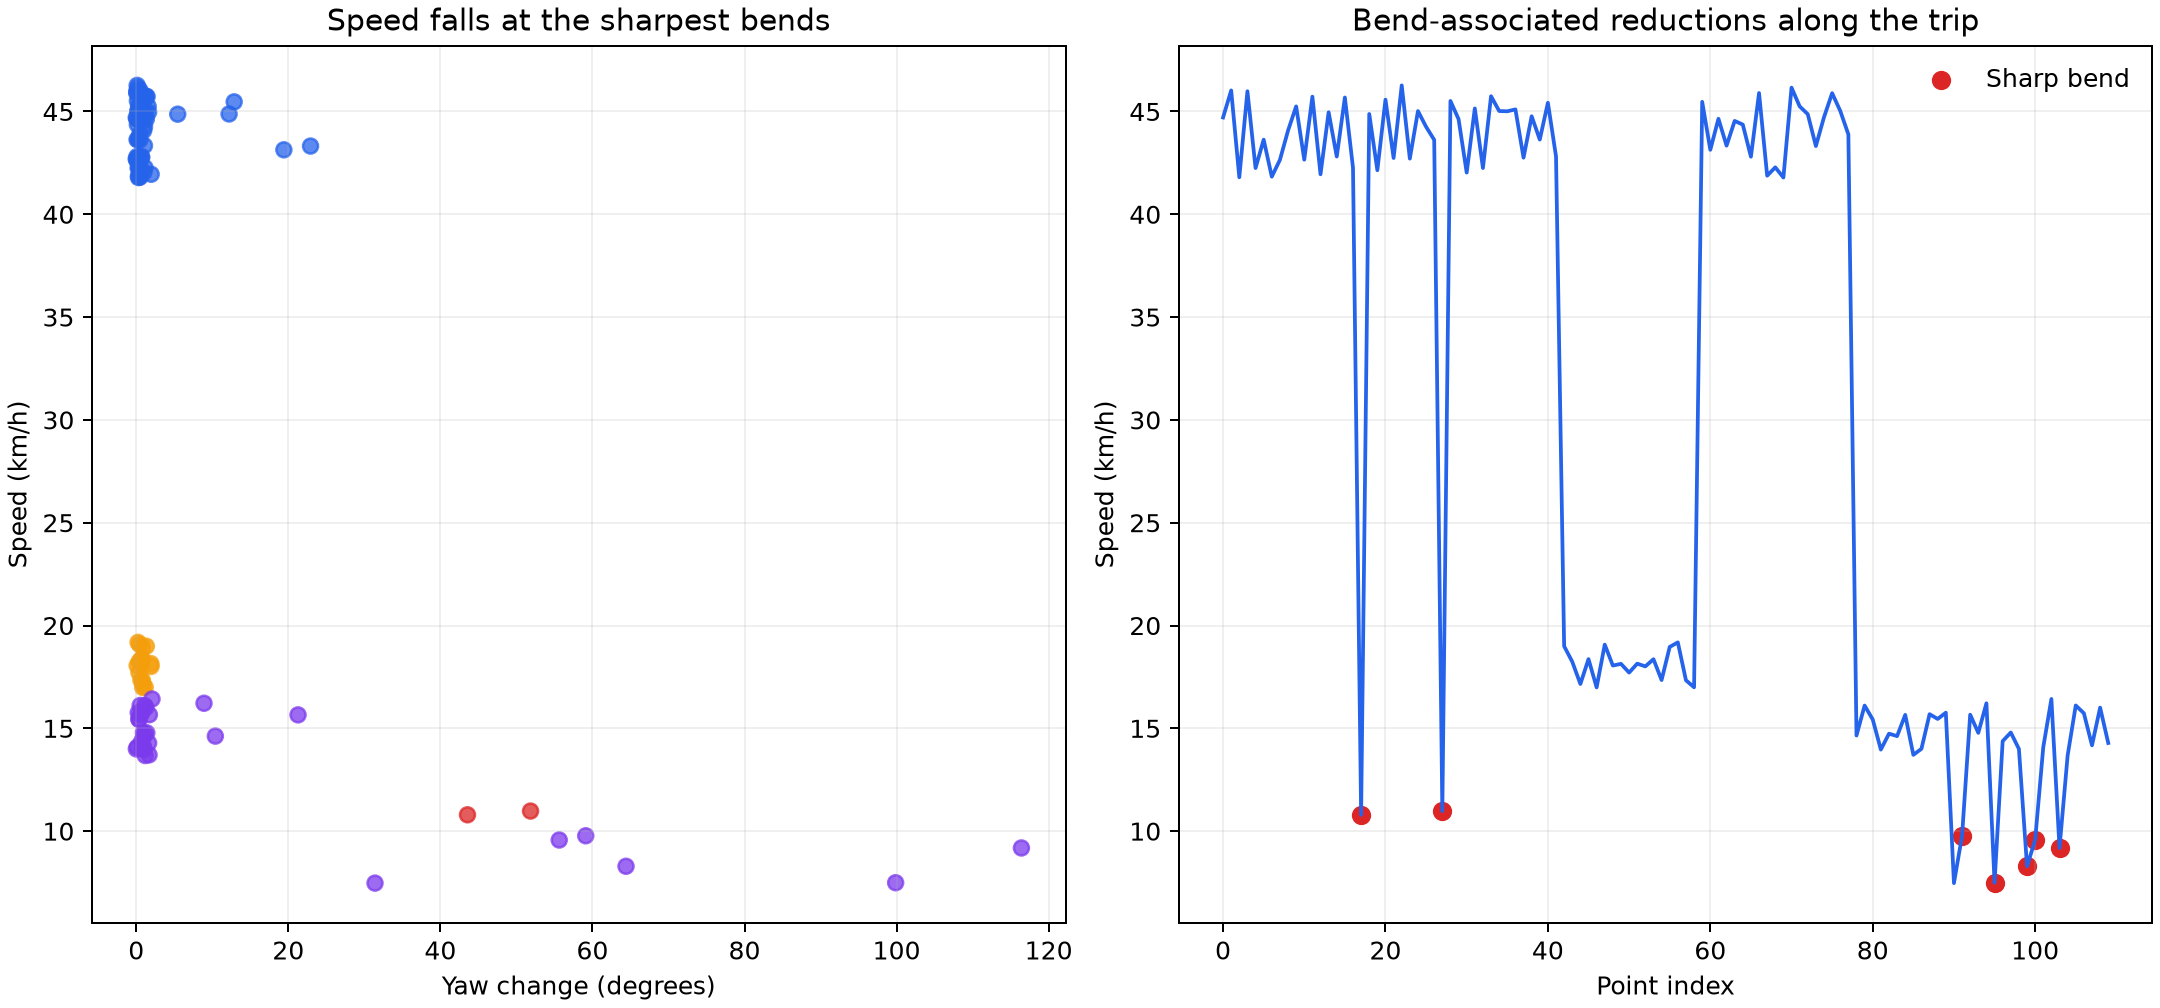

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d=df.copy(); d['bend']=pd.cut(d.yaw_change_deg,[-1,10,35,181],labels=['straight','moderate','sharp']); print(d.groupby('bend').speed_kmh.mean()); plt.scatter(d.yaw_change_deg,d.speed_kmh,c=pd.Categorical(d.bend).codes); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/speed_vs_bends.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "speed_turn_relationship",
  "insight": "The strongest speed reductions consistently occur around the sharpest bends in the route, while movement remains relatively stable along straight road sections.",
  "insight_value": {
    "sharp_bend_speed_mean_kmh": 9.44,
    "straight_speed_mean_kmh": 32.19
  },
  "plot": {
    "plot_type": "speed_turn_relationship",
    "title": "Speed Reductions and Route Bends",
    "file": "visualizations/speed_vs_bends.png",
    "description": "Yaw-change and speed evidence is shown both as a relationship and along the trip sequence."
  },
  "question": "Where do the largest speed reductions occur relative to route curvature?",
  "actionable_insight": "Compare speed distributions at high-yaw and low-yaw points and check their positions in the sequence.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd=df.copy(); d['bend']=pd.cut(d.yaw_change_deg,[-1,10,35,181],labels=['straight','moderate','sharp']); print(d.groupby('bend').speed_kmh.mean()); plt.scatter(d.yaw_change_deg,d.speed_kmh,c=pd.Categorical(d.bend).codes); plt.show()",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_timestamp"
  ]
}

### **Question 2**: Which part of the journey contributes most of the repeated turns and excess travel distance?

#### Analysis action

Relate destination-area geometry to the speed phase and to per-step additions of excess distance.

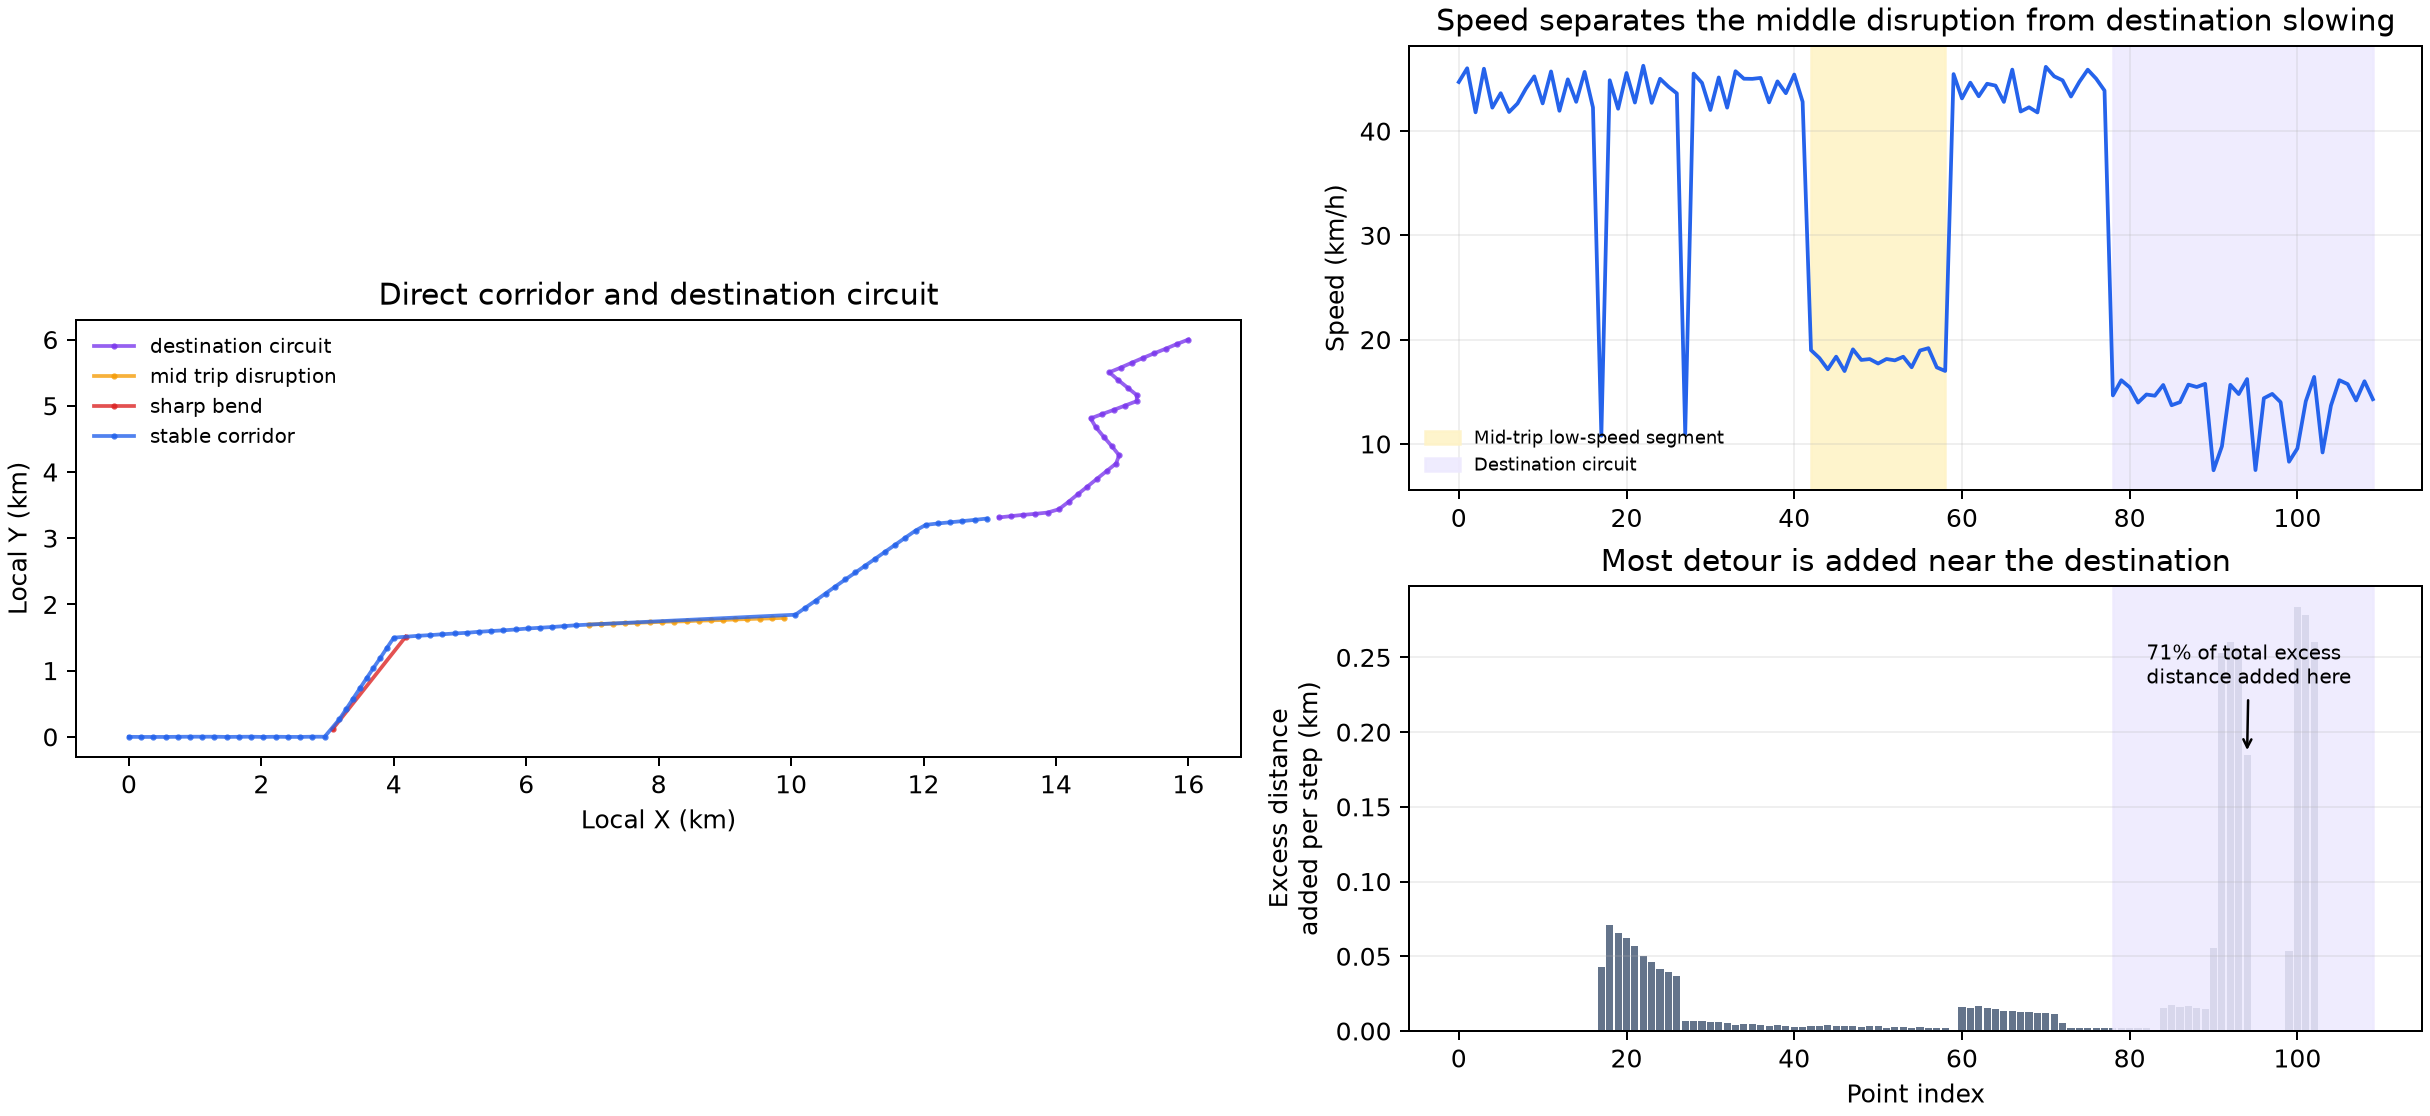

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d=df.copy(); d['excess_added_km']=d.excess_distance_km.diff().fillna(0); fig,ax=plt.subplots(2,2); ax[0,0].plot(d.x_km,d.y_km); ax[0,1].plot(d.point_index,d.speed_kmh); ax[1,1].bar(d.point_index,d.excess_added_km); plt.show(); print(d.groupby('movement_phase').yaw_change_deg.mean())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/destination_circuit_excess.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "destination_circuit_geometry",
  "insight": "The trip remains direct for most of the journey but becomes slow and locally circuitous near the destination, where repeated turns account for most of the excess travel distance.",
  "insight_value": {
    "destination_phase_start_point": 78,
    "share_of_excess_distance_added_near_destination": 0.71
  },
  "plot": {
    "plot_type": "destination_circuit_geometry",
    "title": "Destination Circuit, Speed, and Excess Distance",
    "file": "visualizations/destination_circuit_excess.png",
    "description": "The route map is paired with the same speed sequence used for the mid-trip-disruption view and with per-step excess-distance additions, separating the middle slowdown from destination-area detours."
  },
  "question": "Which part of the journey contributes most of the repeated turns and excess travel distance?",
  "actionable_insight": "Relate destination-area geometry to the speed phase and to per-step additions of excess distance.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd=df.copy(); d['excess_added_km']=d.excess_distance_km.diff().fillna(0); fig,ax=plt.subplots(2,2); ax[0,0].plot(d.x_km,d.y_km); ax[0,1].plot(d.point_index,d.speed_kmh); ax[1,1].bar(d.point_index,d.excess_added_km); plt.show(); print(d.groupby('movement_phase').yaw_change_deg.mean())",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_timestamp"
  ]
}

### **Question 3**: Is there a prolonged low-speed interval away from the destination, and how does movement before and after it compare?

#### Analysis action

Compare the highlighted interval with adjacent stable-corridor speeds and with the later destination phase.

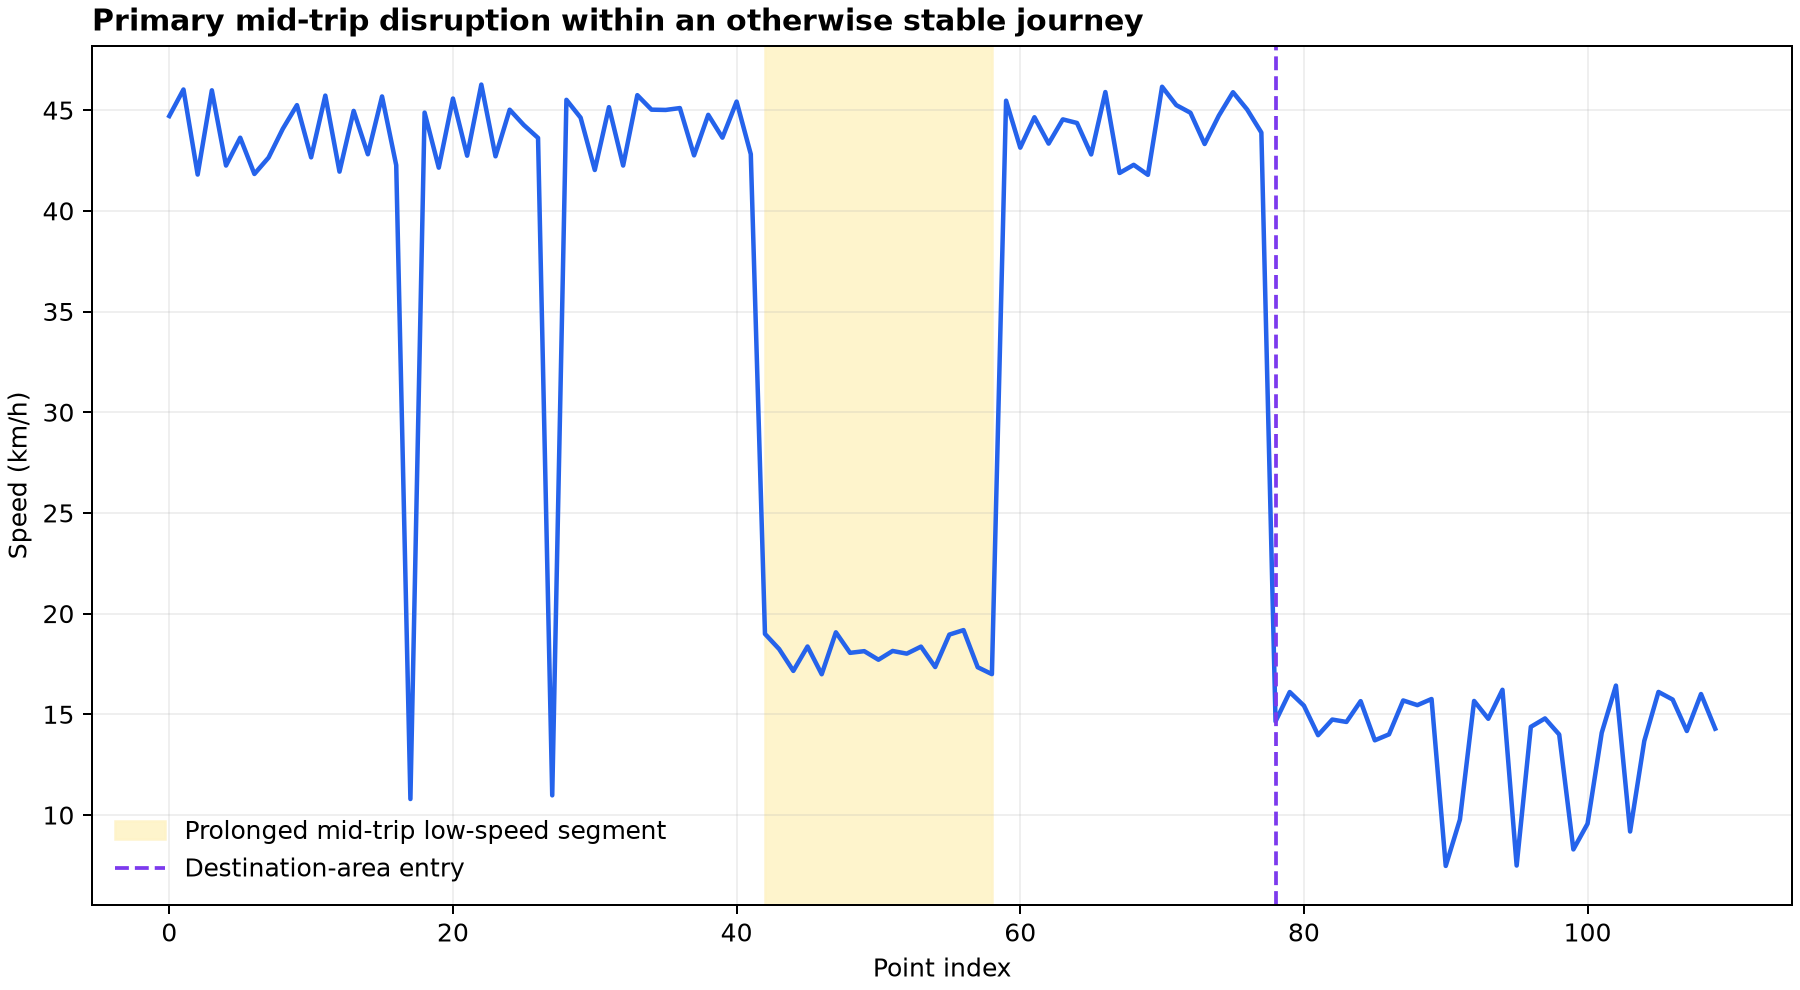

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d=df.copy(); d['mid_disruption']=d.point_index.between(42,58); print(d.groupby('mid_disruption').speed_kmh.mean()); plt.plot(d.point_index,d.speed_kmh); plt.axvspan(42,58,color='orange',alpha=.25); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/mid_trip_low_speed_disruption.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "speed_phase_disruption",
  "insight": "A prolonged low-speed segment appears in the middle of the trip despite relatively smooth movement before and after it, making this section the primary disruption to an otherwise stable journey.",
  "insight_value": {
    "low_speed_segment_points": [
      42,
      58
    ],
    "mean_segment_speed_kmh": 18.06
  },
  "plot": {
    "plot_type": "speed_phase_disruption",
    "title": "Mid-Trip Low-Speed Disruption",
    "file": "visualizations/mid_trip_low_speed_disruption.png",
    "description": "A highlighted continuous interval distinguishes the prolonged mid-trip disruption from brief bend-related reductions."
  },
  "question": "Is there a prolonged low-speed interval away from the destination, and how does movement before and after it compare?",
  "actionable_insight": "Compare the highlighted interval with adjacent stable-corridor speeds and with the later destination phase.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd=df.copy(); d['mid_disruption']=d.point_index.between(42,58); print(d.groupby('mid_disruption').speed_kmh.mean()); plt.plot(d.point_index,d.speed_kmh); plt.axvspan(42,58,color='orange',alpha=.25); plt.show()",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "gps_position"
  ]
}

### Summary of Findings (Flag 9)

The journey is mostly stable and direct, but three movement changes stand out: brief speed reductions at sharp bends, a prolonged low-speed disruption in the middle, and a slow, repeatedly turning destination phase where most excess distance accumulates.